<a href="https://colab.research.google.com/github/Dharanishh/dharanish_amypo/blob/main/DHARANISH_DAY_6_UNSUPERVISED_LEARNING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

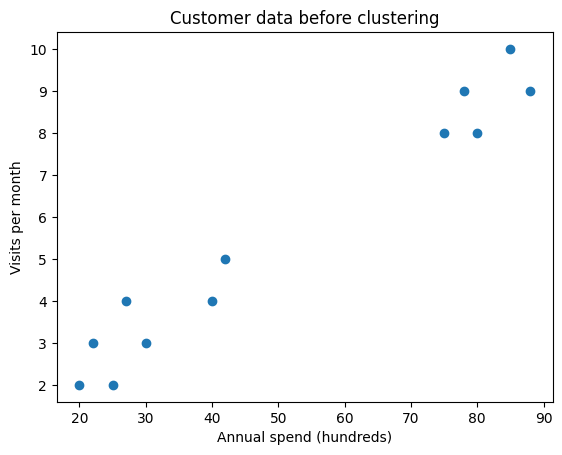

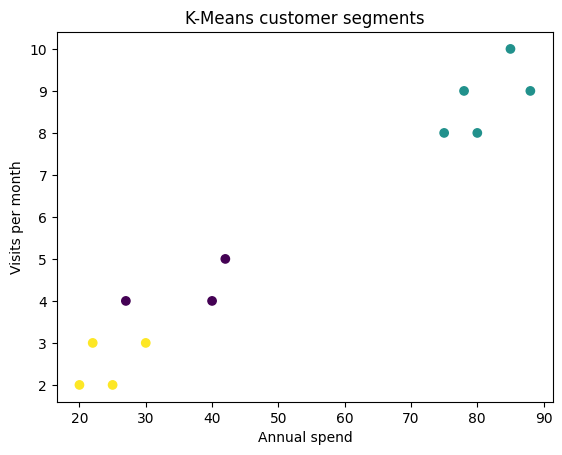

    AnnualSpend  VisitsPerMonth  Cluster
0            20               2        2
1            22               3        2
2            25               2        2
3            27               4        0
4            30               3        2
5            75               8        1
6            78               9        1
7            80               8        1
8            85              10        1
9            88               9        1
10           40               4        0
11           42               5        0
2 inertia: 2.03 silhouette: 0.786
3 inertia: 0.97 silhouette: 0.591
4 inertia: 0.66 silhouette: 0.449
5 inertia: 0.38 silhouette: 0.4
Cluster labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Noise points: 0


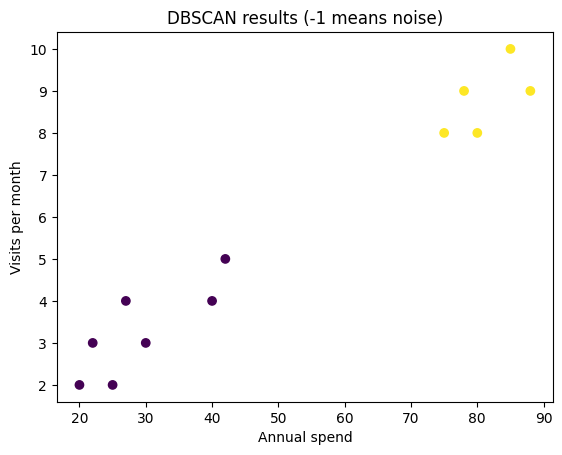

Explained variance: [0.73  0.229]


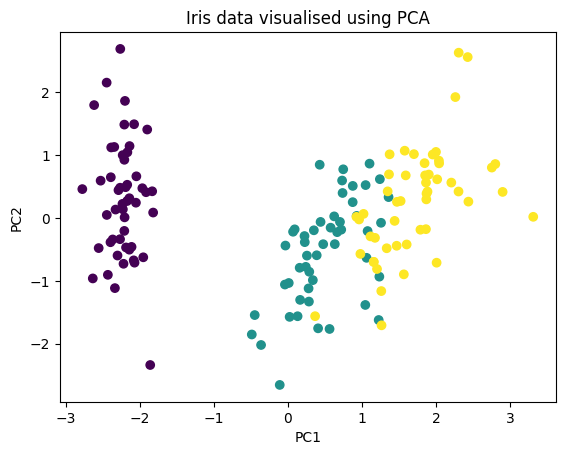

[20  2] Normal
[22  3] Normal
[18  2] Normal
[25  3] Normal
[21  2] Normal
[23  4] Normal
[19  3] Normal
[250  20] Anomaly
    AnnualSpend  VisitsPerMonth
0            20               2
1            25               2
2            28               3
3            30               3
4            35               4
5            40               4
6            45               5
7            48               5
8            50               6
9            55               6
10           60               7
11           65               7
12           70               8
13           75               8
14           80               9
15           85               9
16           90              10
17           95              10
18          100              11
19          110              12


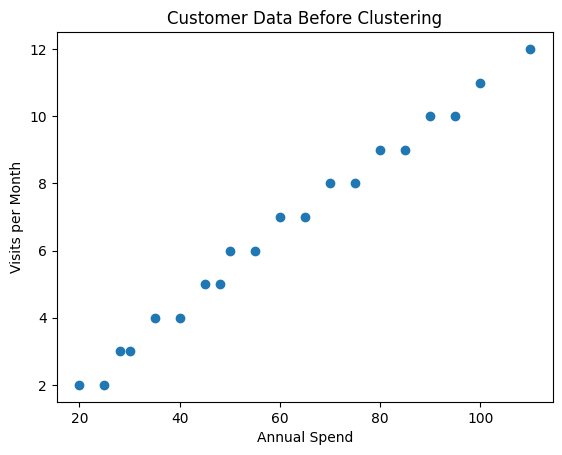

    AnnualSpend  VisitsPerMonth  Cluster
0            20               2        1
1            25               2        1
2            28               3        1
3            30               3        1
4            35               4        1
5            40               4        1
6            45               5        1
7            48               5        1
8            50               6        2
9            55               6        2
10           60               7        2
11           65               7        2
12           70               8        2
13           75               8        2
14           80               9        0
15           85               9        0
16           90              10        0
17           95              10        0
18          100              11        0
19          110              12        0


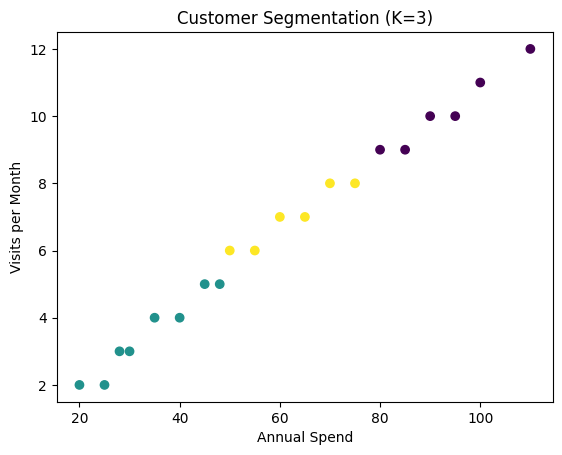

Average Spending for Each Cluster:
Cluster
0    93.333333
1    33.875000
2    62.500000
Name: AnnualSpend, dtype: float64
K = 2 Inertia = 10.27 Silhouette Score = 0.588
K = 3 Inertia = 4.84 Silhouette Score = 0.512
K = 4 Inertia = 2.66 Silhouette Score = 0.485


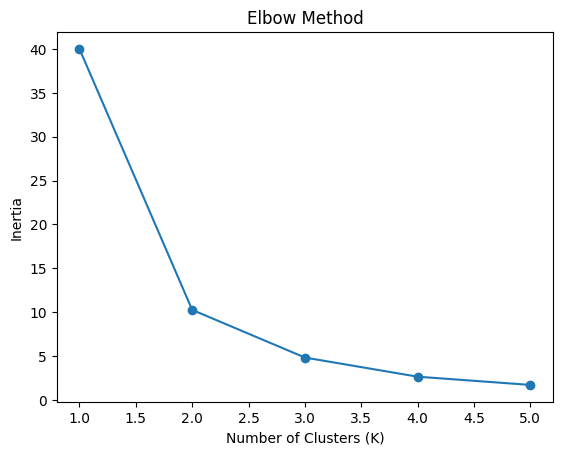

DBSCAN Labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Noise Points: 0


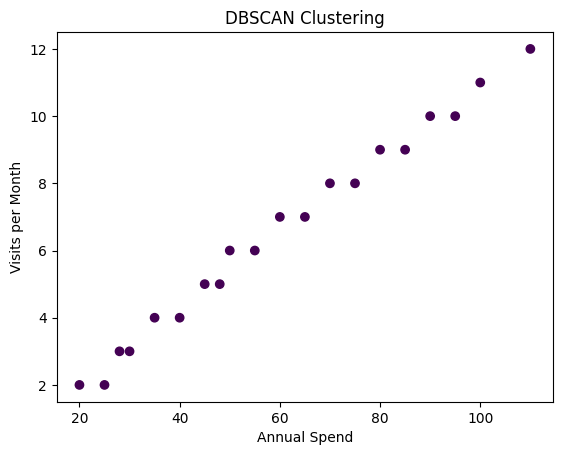

-1 represents noise points that do not belong to any cluster.


In [19]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.DataFrame({
    "AnnualSpend": [20,22,25,27,30,75,78,80,85,88,40,42],
    "VisitsPerMonth": [2,3,2,4,3,8,9,8,10,9,4,5]
})
plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"])
plt.xlabel("Annual spend (hundreds)")
plt.ylabel("Visits per month")
plt.title("Customer data before clustering")
plt.show()

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)

km = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster"] = km.fit_predict(X_scaled)

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=customers["Cluster"])
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("K-Means customer segments")
plt.show()
print(customers)

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    print(k,
          "inertia:", round(model.inertia_, 2),
          "silhouette:", round(silhouette_score(X_scaled, labels), 3))

from sklearn.cluster import DBSCAN
db = DBSCAN(eps=0.8, min_samples=2)
db_labels = db.fit_predict(X_scaled)

print("Cluster labels:", db_labels)
print("Noise points:", sum(db_labels == -1))

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=db_labels)
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("DBSCAN results (-1 means noise)")
plt.show()

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_iris)

print("Explained variance:",
      pca.explained_variance_ratio_.round(3))
plt.scatter(X_2d[:,0], X_2d[:,1], c=iris.target)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Iris data visualised using PCA")
plt.show()

from sklearn.ensemble import IsolationForest
import numpy as np

transactions = np.array([
    [20, 2], [22, 3], [18, 2], [25, 3],
    [21, 2], [23, 4], [19, 3], [250, 20]
])

detector = IsolationForest(contamination=0.12, random_state=42)
labels = detector.fit_predict(transactions)

for row, label in zip(transactions, labels):
    print(row, "Anomaly" if label == -1 else "Normal")


import pandas as pd
import matplotlib.pyplot as plt

customers = pd.DataFrame({
    "AnnualSpend": [20,25,28,30,35,40,45,48,50,55,60,65,70,75,80,85,90,95,100,110],
    "VisitsPerMonth": [2,2,3,3,4,4,5,5,6,6,7,7,8,8,9,9,10,10,11,12]
})

print(customers)

plt.scatter(customers["AnnualSpend"], customers["VisitsPerMonth"])
plt.xlabel("Annual Spend")
plt.ylabel("Visits per Month")
plt.title("Customer Data Before Clustering")
plt.show()

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)

from sklearn.cluster import KMeans

km = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster"] = km.fit_predict(X_scaled)

print(customers)

plt.scatter(customers["AnnualSpend"], customers["VisitsPerMonth"], c=customers["Cluster"])
plt.xlabel("Annual Spend")
plt.ylabel("Visits per Month")
plt.title("Customer Segmentation (K=3)")
plt.show()

print("Average Spending for Each Cluster:")
print(customers.groupby("Cluster")["AnnualSpend"].mean())

from sklearn.metrics import silhouette_score

for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    print("K =", k,
          "Inertia =", round(model.inertia_, 2),
          "Silhouette Score =", round(silhouette_score(X_scaled, labels), 3))

inertia = []

for k in range(1, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 6), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.8, min_samples=2)
db_labels = db.fit_predict(X_scaled)

print("DBSCAN Labels:", db_labels)
print("Noise Points:", sum(db_labels == -1))

plt.scatter(customers["AnnualSpend"], customers["VisitsPerMonth"], c=db_labels)
plt.xlabel("Annual Spend")
plt.ylabel("Visits per Month")
plt.title("DBSCAN Clustering")
plt.show()

print("-1 represents noise points that do not belong to any cluster.")